# Etapa 1 · Análisis exploratorio, preprocesamiento y detección de *data leakage*

**Proyecto integrador — Heart Failure Prediction (MLOps local)**

Objetivo del cuaderno:

1. Explorar el dataset *Heart Failure Prediction* (Kaggle, fedesoriano; 918 pacientes, 11 predictores) y tratar los valores faltantes.
2. Demostrar empíricamente el efecto de la fuga de datos (*data leakage*), comparando un flujo incorrecto con uno correcto basado en `Pipeline`.
3. Implementar, dentro del flujo sin fuga, cuatro clasificadores (LogisticRegression, RandomForestClassifier, KNeighborsClassifier y GradientBoostingClassifier), cada uno en un `Pipeline` optimizado con `GridSearchCV`, y presentar un ranking comparativo por AUC y *accuracy*.

La lógica reutilizable (carga, partición, preprocesamiento, entrenamiento y comparación) se define como funciones en la sección 0 de este cuaderno.

In [1]:
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, accuracy_score, RocCurveDisplay


warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

## 0. Funciones reutilizables

Siguiendo el enunciado, la lógica de carga, partición, preprocesamiento, entrenamiento y comparación se encapsula en funciones. Todo el preprocesamiento (imputación, one-hot y escalado) vive dentro de un `Pipeline`/`ColumnTransformer`, de modo que en cada pliegue de la validación cruzada se ajusta únicamente con los datos de entrenamiento de ese pliegue.

In [2]:
# Funciones reutilizables de la Etapa 1 (carga, partición, preprocesamiento, modelos, entrenamiento)
from time import perf_counter

import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder

RANDOM_STATE = 42
TARGET = "HeartDisease"

# En este dataset un 0 en colesterol o presión en reposo no es fisiológicamente
# posible: es un valor faltante codificado como 0. Se imputa dentro del pipeline.
ZERO_AS_MISSING_COLS = ["RestingBP", "Cholesterol"]
NUMERIC_COLS = ["Age", "MaxHR", "Oldpeak"]
CATEGORICAL_COLS = ["Sex", "ChestPainType", "FastingBS", "RestingECG",
                    "ExerciseAngina", "ST_Slope"]
FEATURES = ["Age", "Sex", "ChestPainType", "RestingBP", "Cholesterol", "FastingBS",
            "RestingECG", "MaxHR", "ExerciseAngina", "Oldpeak", "ST_Slope"]

# ---------------------------------------------------------------------------
# Datos
# ---------------------------------------------------------------------------
def load_data(path) -> pd.DataFrame:
    """Carga el CSV de Kaggle (fedesoriano) y valida sus columnas."""
    if not Path(path).exists():
        raise FileNotFoundError(
            "No se encontró heart.csv. Descárgalo de Kaggle (Heart Failure Prediction) "
            "y colócalo en la carpeta notebooks/."
        )
    df = pd.read_csv(path)
    missing = set(FEATURES + [TARGET]) - set(df.columns)
    if missing:
        raise ValueError(f"Faltan columnas en el dataset: {missing}")
    return df


def split_data(df: pd.DataFrame, test_size: float = 0.2,
               random_state: int = RANDOM_STATE):
    """Separa X/y y hace la partición estratificada ANTES de cualquier ajuste."""
    X = df[FEATURES].copy()
    y = df[TARGET].copy()
    return train_test_split(X, y, test_size=test_size,
                            random_state=random_state, stratify=y)


# ---------------------------------------------------------------------------
# Preprocesamiento
# ---------------------------------------------------------------------------
def build_preprocessor(scaler=None, scale_numeric: bool = True) -> ColumnTransformer:
    """Construye el preprocesamiento sin aprender información fuera del pipeline.

    Los modelos basados en distancias o coeficientes usan escalado. Los árboles
    reciben las variables numéricas sin escalar porque no lo necesitan.
    """
    scaler = scaler if scaler is not None else MinMaxScaler()
    scaler_step = clone(scaler) if scale_numeric else "passthrough"

    zero_missing_pipe = Pipeline([
        ("imputer", SimpleImputer(missing_values=0, strategy="median")),
        ("scaler", scaler_step),
    ])
    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", clone(scaler) if scale_numeric else "passthrough"),
    ])
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", drop="if_binary")),
    ])
    return ColumnTransformer([
        ("num_zero", zero_missing_pipe, ZERO_AS_MISSING_COLS),
        ("num", numeric_pipe, NUMERIC_COLS),
        ("cat", categorical_pipe, CATEGORICAL_COLS),
    ])


# ---------------------------------------------------------------------------
# Modelos y mallas de hiperparámetros
# ---------------------------------------------------------------------------
def get_models():
    """Devuelve (modelo, malla, requiere_escalado) para cada clasificador."""
    rs = RANDOM_STATE
    return {
        "LogisticRegression": (
            LogisticRegression(max_iter=2000, random_state=rs),
            {"clf__C": [0.01, 0.1, 1, 10]},
            True,
        ),
        "KNN": (
            KNeighborsClassifier(),
            {"clf__n_neighbors": [5, 11, 21, 31], "clf__weights": ["uniform", "distance"]},
            True,
        ),
        "RandomForest": (
            RandomForestClassifier(random_state=rs),
            {"clf__n_estimators": [200, 400], "clf__max_depth": [4, 8, None],
             "clf__min_samples_leaf": [1, 5]},
            False,
        ),
        "GradientBoosting": (
            GradientBoostingClassifier(random_state=rs),
            {"clf__n_estimators": [100, 200], "clf__learning_rate": [0.05, 0.1],
             "clf__max_depth": [2, 3]},
            False,
        ),
    }


def make_cv(n_splits: int = 5) -> StratifiedKFold:
    return StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)


# ---------------------------------------------------------------------------
# Entrenamiento y evaluación
# ---------------------------------------------------------------------------
def train_pipeline(X_train, y_train, model, param_grid, preprocessor=None,
                   cv=None, scoring="roc_auc", n_jobs=-1,
                   scale_numeric: bool = True) -> GridSearchCV:
    """Pipeline(preprocesamiento + modelo) optimizado con GridSearchCV."""
    pipe = Pipeline([
        ("preprocess", preprocessor if preprocessor is not None
         else build_preprocessor(scale_numeric=scale_numeric)),
        ("clf", model),
    ])
    refit = "roc_auc" if isinstance(scoring, dict) else True
    grid = GridSearchCV(pipe, param_grid, cv=cv or make_cv(), scoring=scoring,
                        n_jobs=n_jobs, refit=refit)
    grid.fit(X_train, y_train)
    return grid


def evaluate(model, X, y, threshold: float = 0.5) -> dict:
    """AUC y accuracy de un estimador ya ajustado."""
    proba = model.predict_proba(X)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {"auc": roc_auc_score(y, proba), "accuracy": accuracy_score(y, pred)}


def compare_models(X_train, y_train, models=None):
    """Compara modelos solo con validación cruzada del conjunto de entrenamiento."""
    models = models or get_models()
    results, grids = [], {}
    scoring = {"roc_auc": "roc_auc", "accuracy": "accuracy"}
    for name, (model, grid_params, scale_numeric) in models.items():
        t0 = perf_counter()
        grid = train_pipeline(
            X_train,
            y_train,
            model,
            grid_params,
            scoring=scoring,
            scale_numeric=scale_numeric,
        )
        elapsed = perf_counter() - t0
        best = grid.best_index_
        results.append({
            "modelo": name,
            "auc_cv": grid.best_score_,
            "auc_cv_std": grid.cv_results_["std_test_roc_auc"][best],
            "accuracy_cv": grid.cv_results_["mean_test_accuracy"][best],
            "accuracy_cv_std": grid.cv_results_["std_test_accuracy"][best],
            "mejores_parametros": {k.replace("clf__", ""): v
                                   for k, v in grid.best_params_.items()},
            "tiempo_s": round(elapsed, 1),
        })
        grids[name] = grid
    ranking = (pd.DataFrame(results)
               .sort_values("auc_cv", ascending=False)
               .reset_index(drop=True))
    ranking.index = np.arange(1, len(ranking) + 1)
    ranking.index.name = "ranking"
    return ranking, grids


def feature_names(fitted_pipeline):
    """Nombres de las variables tras el ColumnTransformer."""
    return list(fitted_pipeline.named_steps["preprocess"].get_feature_names_out())


## 1. Carga y descripción del dataset

In [3]:
df = load_data(ROOT / "notebooks" / "heart.csv")
print("Dimensiones:", df.shape)
df.head()

Dimensiones: (918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


| Variable | Descripción | Tipo |
|---|---|---|
| `Age` | Edad del paciente (años) | Numérica |
| `Sex` | Sexo (M / F) | Categórica |
| `ChestPainType` | Tipo de dolor torácico: TA (angina típica), ATA (atípica), NAP (no anginoso), ASY (asintomático) | Categórica |
| `RestingBP` | Presión arterial en reposo (mm Hg) | Numérica |
| `Cholesterol` | Colesterol sérico (mg/dl) | Numérica |
| `FastingBS` | Glucosa en ayunas > 120 mg/dl (1) o no (0) | Binaria |
| `RestingECG` | Electrocardiograma en reposo: Normal, ST, LVH | Categórica |
| `MaxHR` | Frecuencia cardíaca máxima alcanzada | Numérica |
| `ExerciseAngina` | Angina inducida por ejercicio (Y / N) | Categórica |
| `Oldpeak` | Depresión del segmento ST | Numérica |
| `ST_Slope` | Pendiente del segmento ST en ejercicio: Up, Flat, Down | Categórica |
| **`HeartDisease`** | **Variable objetivo: 1 = enfermedad cardíaca, 0 = normal** | Binaria |

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [5]:
df.describe().T.style.format("{:.2f}").set_caption("Estadísticos descriptivos de las variables numéricas")

,count,mean,std,min,25%,50%,75%,max
Age,918.00,53.51,9.43,28.00,47.00,54.00,60.00,77.00
RestingBP,918.00,132.40,18.51,0.00,120.00,130.00,140.00,200.00
Cholesterol,918.00,198.80,109.38,0.00,173.25,223.00,267.00,603.00
FastingBS,918.00,0.23,0.42,0.00,0.00,0.00,0.00,1.00
MaxHR,918.00,136.81,25.46,60.00,120.00,138.00,156.00,202.00
Oldpeak,918.00,0.89,1.07,-2.60,0.00,0.60,1.50,6.20
HeartDisease,918.00,0.55,0.50,0.00,0.00,1.00,1.00,1.00


,n,%
HeartDisease,,
Enfermedad (1),508,55.3
Normal (0),410,44.7


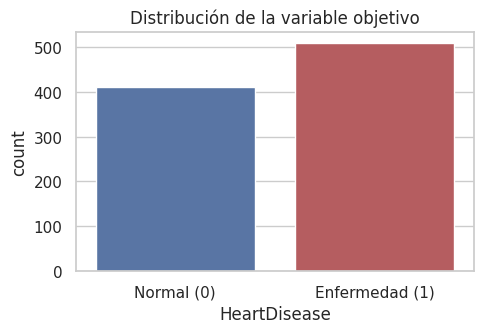

In [6]:
dist = df[TARGET].value_counts().rename({0: "Normal (0)", 1: "Enfermedad (1)"}).to_frame("n")
dist["%"] = (dist["n"] / len(df) * 100).round(1)
display(dist)

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(x=TARGET, data=df, ax=ax, palette=["#4C72B0", "#C44E52"])
ax.set_xticklabels(["Normal (0)", "Enfermedad (1)"])
ax.set_title("Distribución de la variable objetivo")
plt.tight_layout(); plt.show()

La clase positiva representa ~55 % de los pacientes: el desbalance es leve, por lo que no se requiere remuestreo. Aun así, toda partición se hace **estratificada** (`stratify=y` y `StratifiedKFold`) para conservar la proporción de clases.

## 2. Valores faltantes (explícitos y ocultos)

In [7]:
faltantes = pd.DataFrame({
    "NaN explícitos": df.isna().sum(),
    "Ceros": (df[FEATURES] == 0).sum(),
})
faltantes["% ceros"] = (faltantes["Ceros"] / len(df) * 100).round(1)
faltantes.style.bar(subset=["% ceros"], color="#c0392b", vmin=0, vmax=100) \
    .set_caption("Valores faltantes y ceros por variable")

,NaN explícitos,Ceros,% ceros
Age,0,0.000000,0.000000
ChestPainType,0,0.000000,0.000000
Cholesterol,0,172.000000,18.700000
ExerciseAngina,0,0.000000,0.000000
FastingBS,0,704.000000,76.700000
HeartDisease,0,nan,nan
MaxHR,0,0.000000,0.000000
Oldpeak,0,368.000000,40.100000
RestingBP,0,1.000000,0.100000
RestingECG,0,0.000000,0.000000


El dataset no tiene `NaN` explícitos, pero sí **faltantes ocultos**: un colesterol sérico de 0 mg/dl o una presión en reposo de 0 mm Hg no son fisiológicamente posibles, así que esos ceros son datos no registrados. En cambio, los ceros de `Oldpeak` (sin depresión del ST) y de `FastingBS` (glucosa normal) sí son valores válidos.

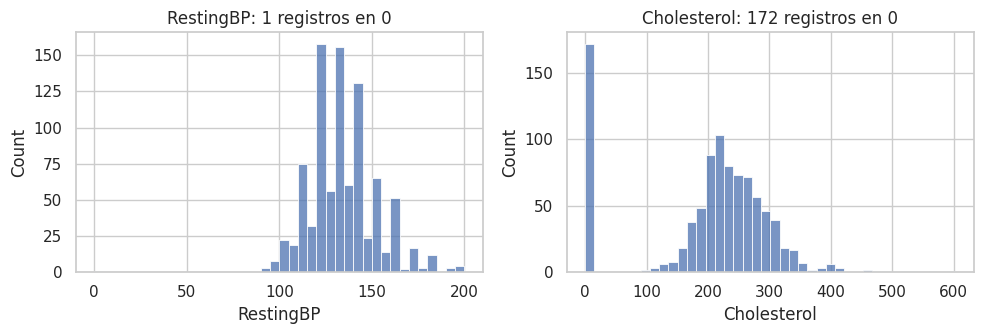

Tasa de enfermedad cuando Cholesterol == 0: 0.884
Tasa de enfermedad cuando Cholesterol  > 0: 0.477


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, col in zip(axes, ZERO_AS_MISSING_COLS):
    sns.histplot(df[col], bins=40, ax=ax, color="#4C72B0")
    ax.set_title(f"{col}: {(df[col] == 0).sum()} registros en 0")
plt.tight_layout(); plt.show()

print("Tasa de enfermedad cuando Cholesterol == 0:", round(df.loc[df.Cholesterol == 0, TARGET].mean(), 3))
print("Tasa de enfermedad cuando Cholesterol  > 0:", round(df.loc[df.Cholesterol > 0, TARGET].mean(), 3))

**Decisión de tratamiento.** No se eliminan filas (se perdería ~19 % de la muestra) ni se imputa antes de la partición, porque la mediana calculada sobre todo el dataset contaminaría el conjunto de prueba. Los ceros de `RestingBP` y `Cholesterol` se imputan **dentro del pipeline** con `SimpleImputer(missing_values=0, strategy="median")`, que aprende la mediana solo con los datos de entrenamiento de cada pliegue. Así el mismo tratamiento se aplica automáticamente a los datos que lleguen a la API en producción.

Observación: los pacientes con colesterol en 0 tienen una tasa de enfermedad mucho mayor; el faltante no es aleatorio (probablemente proviene de una de las cinco bases de origen). Es un hallazgo que conviene reportar, aunque no se modele explícitamente.

## 3. Análisis exploratorio

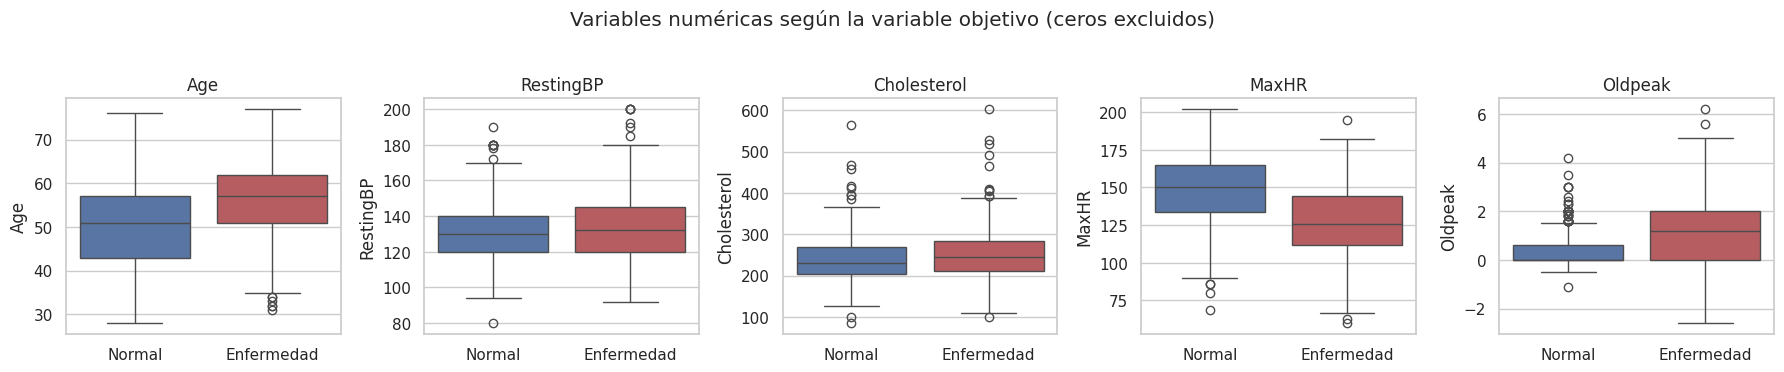

In [9]:
num_cols = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]
fig, axes = plt.subplots(1, 5, figsize=(18, 3.6))
plot_df = df.copy()
plot_df[ZERO_AS_MISSING_COLS] = plot_df[ZERO_AS_MISSING_COLS].replace(0, np.nan)
for ax, col in zip(axes, num_cols):
    sns.boxplot(x=TARGET, y=col, data=plot_df, ax=ax, palette=["#4C72B0", "#C44E52"])
    ax.set_xticklabels(["Normal", "Enfermedad"]); ax.set_xlabel("")
    ax.set_title(col)
plt.suptitle("Variables numéricas según la variable objetivo (ceros excluidos)", y=1.03)
plt.tight_layout(); plt.show()

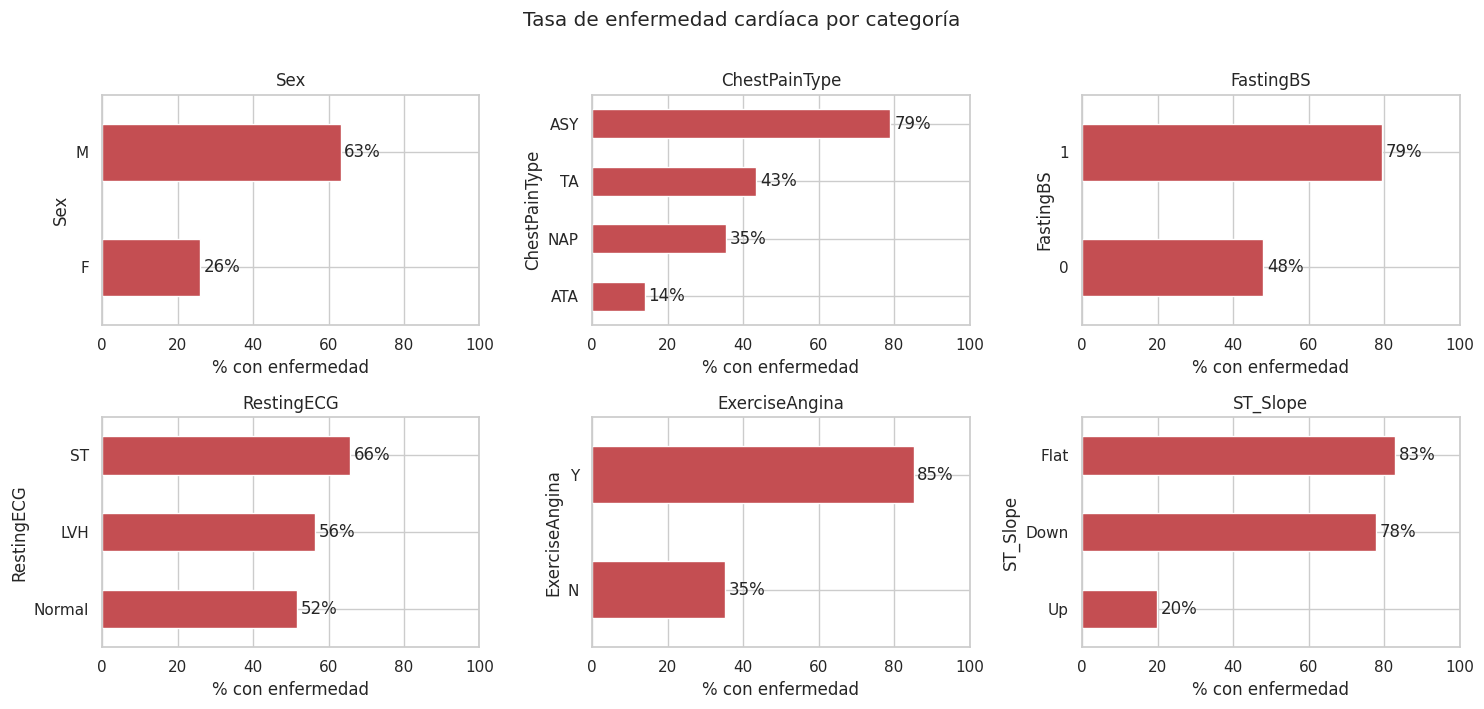

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), CATEGORICAL_COLS):
    tasa = df.groupby(col)[TARGET].mean().sort_values() * 100
    tasa.plot.barh(ax=ax, color="#C44E52")
    ax.set_xlim(0, 100); ax.set_xlabel("% con enfermedad"); ax.set_title(col)
    for i, v in enumerate(tasa):
        ax.text(v + 1, i, f"{v:.0f}%", va="center")
plt.suptitle("Tasa de enfermedad cardíaca por categoría", y=1.01)
plt.tight_layout(); plt.show()

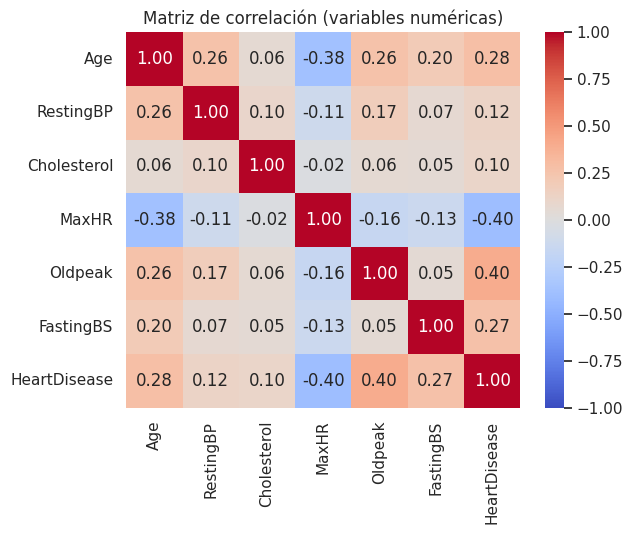

In [11]:
corr = plot_df[num_cols + ["FastingBS", TARGET]].corr()
plt.figure(figsize=(6.5, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de correlación (variables numéricas)")
plt.tight_layout(); plt.show()

**Síntesis del EDA**

- `ST_Slope` (Flat/Down), `ChestPainType = ASY` y `ExerciseAngina = Y` muestran tasas de enfermedad muy altas: serán predictores fuertes.
- `Oldpeak` y `Age` aumentan con la enfermedad y `MaxHR` disminuye, coherente con la fisiología del esfuerzo.
- No hay colinealidad fuerte entre numéricas (|r| < 0.4), así que no hace falta eliminar variables.
- Las escalas son muy distintas (p. ej. `Cholesterol` vs `Oldpeak`), por lo que KNN y la regresión logística usan escalado. Random Forest y Gradient Boosting conservan las magnitudes originales porque los árboles no necesitan escalar.

**Preprocesamiento adoptado (todo dentro de un `ColumnTransformer`):**

| Grupo | Variables | Transformación |
|---|---|---|
| Numéricas con ceros inválidos | `RestingBP`, `Cholesterol` | `SimpleImputer(missing_values=0, median)` y escalado solo en modelos sensibles a escala |
| Numéricas | `Age`, `MaxHR`, `Oldpeak` | `SimpleImputer(median)` y escalado solo en modelos sensibles a escala |
| Categóricas | `Sex`, `ChestPainType`, `FastingBS`, `RestingECG`, `ExerciseAngina`, `ST_Slope` | `SimpleImputer(most_frequent)` → `OneHotEncoder(handle_unknown="ignore", drop="if_binary")` |

Se usa `OneHotEncoder` en lugar de `pd.get_dummies()` porque recuerda las categorías aprendidas en el entrenamiento y tolera categorías nuevas en producción.

## 4. Demostración de *data leakage*

Se reproduce el experimento propuesto en el enunciado: se agrega una variable artificial `leaky_feature = y + ruido`, que contiene la respuesta, y se escala **todo** el dataset antes de partir. Como este dataset tiene variables categóricas, el flujo "con fuga" las codifica con `pd.get_dummies()` también sobre el dataset completo.

### 4.1 Código original y por qué el supuesto flujo «sin fuga» sigue siendo incorrecto

Se ejecuta el flujo del enunciado con solo dos adaptaciones obligatorias para este dataset: la columna objetivo se llama `HeartDisease` (no `target`) y las variables categóricas se codifican con `pd.get_dummies`, porque `MinMaxScaler` y `SVC` no aceptan texto. El segundo resultado **no se interpreta como un escenario válido**: `X` todavía contiene `leaky_feature`.

In [12]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score

# Cargar datos
df = pd.read_csv(ROOT / "notebooks" / "heart.csv")

X = pd.get_dummies(df.drop("HeartDisease", axis=1), drop_first=True, dtype=float)
y = df["HeartDisease"]

# Variable artificial que introduce fuga de objetivo
np.random.seed(0)
X["leaky_feature"] = y + np.random.normal(0, 0.01, size=len(y))

# Fuga de objetivo + preprocesamiento ajustado antes de partir
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)
X_train_l, X_test_l, y_train_l, y_test_l = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y)
grid_l = GridSearchCV(SVC(probability=True),
                      param_grid={"C": [0.1, 1, 10], "gamma": [0.01, 0.1]},
                      cv=5, scoring="roc_auc")
grid_l.fit(X_train_l, y_train_l)
auc_l = roc_auc_score(y_test_l, grid_l.predict_proba(X_test_l)[:, 1])

# El Pipeline arregla el orden del escalado, pero NO elimina leaky_feature
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
pipe = Pipeline([("scaler", MinMaxScaler()), ("svc", SVC(probability=True))])
param_grid = {"svc__C": [0.1, 1, 10], "svc__gamma": [0.01, 0.1]}
grid = GridSearchCV(pipe, param_grid, cv=5, scoring="roc_auc")
grid.fit(X_train, y_train)
auc_pipeline_con_fuga = roc_auc_score(y_test, grid.predict_proba(X_test)[:, 1])

print(f"AUC con fuga de objetivo y preprocesamiento anticipado: {auc_l:.3f}")
print("AUC del supuesto flujo 'sin fuga' (todavía contiene leaky_feature): "
      f"{auc_pipeline_con_fuga:.3f}")

AUC con fuga de objetivo y preprocesamiento anticipado: 1.000
AUC del supuesto flujo 'sin fuga' (todavía contiene leaky_feature): 1.000


El "flujo correcto" de la plantilla también da un AUC cercano a 1 porque `X` todavía contiene `leaky_feature`: el `Pipeline` corrige la fuga de **preprocesamiento** (el escalado), pero no la fuga **de objetivo**. Para separar los dos efectos se repite el experimento en cuatro escenarios.

### 4.2 Separación de los dos tipos de fuga

In [13]:
X_full = df[FEATURES].copy()
y_full = df[TARGET].copy()

np.random.seed(0)
leaky = y_full + np.random.normal(0, 0.01, size=len(y_full))

param_grid_svc = {"C": [0.1, 1, 10], "gamma": [0.01, 0.1]}
cv = make_cv()

def svc_grid_sin_pipeline(X_proc, y):
    """Preprocesamiento ya aplicado a TODO el dataset → split → GridSearch."""
    X_tr, X_te, y_tr, y_te = train_test_split(X_proc, y, test_size=0.2,
                                              random_state=RANDOM_STATE, stratify=y)
    g = GridSearchCV(SVC(probability=True, random_state=RANDOM_STATE), param_grid_svc,
                     cv=cv, scoring="roc_auc")
    g.fit(X_tr, y_tr)
    return g.best_score_, roc_auc_score(y_te, g.predict_proba(X_te)[:, 1])

def svc_grid_con_pipeline(X, y):
    """Split primero → Pipeline (preprocesamiento + SVC) dentro de GridSearch."""
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2,
                                              random_state=RANDOM_STATE, stratify=y)
    extra = [c for c in X.columns if c not in FEATURES]
    pre = build_preprocessor()
    if extra:  # la variable con fuga se escala y entra al modelo
        pre.transformers.append(("leak", MinMaxScaler(), extra))
    pipe = Pipeline([("preprocess", pre), ("svc", SVC(probability=True, random_state=RANDOM_STATE))])
    g = GridSearchCV(pipe, {f"svc__{k}": v for k, v in param_grid_svc.items()},
                     cv=cv, scoring="roc_auc")
    g.fit(X_tr, y_tr)
    return g.best_score_, roc_auc_score(y_te, g.predict_proba(X_te)[:, 1])

def preprocesar_todo(X):
    """Flujo INCORRECTO: imputación, dummies y escalado con estadísticos de todo el dataset."""
    X = X.copy()
    for c in ZERO_AS_MISSING_COLS:
        X[c] = X[c].replace(0, X.loc[X[c] > 0, c].median())
    X = pd.get_dummies(X, columns=CATEGORICAL_COLS, drop_first=True, dtype=float)
    return MinMaxScaler().fit_transform(X)

In [14]:
escenarios = {}

# A) Enunciado: variable con fuga + preprocesamiento antes del split
X_a = X_full.assign(leaky_feature=leaky)
escenarios["A. Fuga de objetivo + preprocesamiento antes del split"] = svc_grid_sin_pipeline(preprocesar_todo(X_a), y_full)

# B) Fuga de objetivo, aunque el preprocesamiento esté en un Pipeline
escenarios["B. Fuga de objetivo con Pipeline"] = svc_grid_con_pipeline(X_a, y_full)

# C) Sin variable con fuga, pero preprocesamiento antes del split
escenarios["C. Solo fuga de preprocesamiento"] = svc_grid_sin_pipeline(preprocesar_todo(X_full), y_full)

# D) Flujo correcto: sin variable con fuga, split primero, todo en Pipeline
escenarios["D. Flujo correcto (sin fuga)"] = svc_grid_con_pipeline(X_full, y_full)

tabla_fuga = pd.DataFrame(escenarios, index=["AUC validación cruzada", "AUC prueba"]).T
tabla_fuga.style.format("{:.3f}").background_gradient(cmap="Reds", vmin=0.85, vmax=1) \
    .set_caption("Efecto de la fuga de datos sobre el AUC de un SVC")

,AUC validación cruzada,AUC prueba
A. Fuga de objetivo + preprocesamiento antes del split,1.000,1.000
B. Fuga de objetivo con Pipeline,1.000,1.000
C. Solo fuga de preprocesamiento,0.916,0.930
D. Flujo correcto (sin fuga),0.919,0.918


**Interpretación**

- **A y B**: con la variable que contiene la respuesta el AUC llega prácticamente a 1, **con o sin `Pipeline`**. El pipeline no corrige la fuga de objetivo; esa se evita revisando qué variables estarían realmente disponibles al momento de predecir (aquí, ninguna variable posterior al diagnóstico).
- **C vs D**: con escalado, imputación y codificación sobre todo el dataset, la diferencia frente al flujo correcto es pequeña en este caso, porque `MinMaxScaler` y la mediana cambian poco entre particiones. Pero el procedimiento sigue siendo inválido: la estimación deja de ser honesta y, con transformaciones que usan la respuesta o con selección de variables, la distorsión puede ser grande.
- **D** es el valor que debe reportarse: partición primero y todo el preprocesamiento dentro del `Pipeline`, reajustado en cada pliegue.

## 5. Comparación de modelos en el flujo sin fuga

Cada modelo se encapsula en `Pipeline([("preprocess", ColumnTransformer), ("clf", modelo)])` y se optimiza con `GridSearchCV` y `StratifiedKFold` de 5 pliegues. La búsqueda calcula AUC y Accuracy, pero usa `refit="roc_auc"`: el ganador se elige **exclusivamente por AUC de validación cruzada sobre entrenamiento**.

El conjunto Test queda reservado y no se evalúa aquí; se utiliza una sola vez en la Etapa 2, después de seleccionar el ganador. La regresión logística y KNN usan `MinMaxScaler`; Random Forest y Gradient Boosting no escalan las numéricas.

In [15]:
X_train, X_test, y_train, y_test = split_data(df)
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)
print(f"Proporción de positivos — train: {y_train.mean():.3f} | test: {y_test.mean():.3f}")

Entrenamiento: (734, 11) | Prueba: (184, 11)
Proporción de positivos — train: 0.553 | test: 0.554


In [16]:
ranking, grids = compare_models(X_train, y_train)

(ranking.drop(columns=["mejores_parametros"])
 .style.format({"auc_cv": "{:.4f}", "auc_cv_std": "{:.4f}",
                "accuracy_cv": "{:.4f}", "accuracy_cv_std": "{:.4f}",
                "tiempo_s": "{:.1f}"})
 .background_gradient(subset=["auc_cv", "accuracy_cv"], cmap="Greens")
 .set_caption("Ranking de modelos: solo validación cruzada del conjunto de entrenamiento"))

,modelo,auc_cv,auc_cv_std,accuracy_cv,accuracy_cv_std,tiempo_s
ranking,,,,,,
1,RandomForest,0.9316,0.0264,0.8529,0.0431,29.3
2,GradientBoosting,0.9269,0.0305,0.8570,0.0285,10.0
3,LogisticRegression,0.9227,0.0350,0.8515,0.0311,1.0
4,KNN,0.9169,0.0393,0.8529,0.0293,1.7


In [17]:
pd.DataFrame({"modelo": ranking["modelo"], "mejores hiperparámetros": ranking["mejores_parametros"].astype(str)})

,modelo,mejores hiperparámetros
ranking,,
1,RandomForest,"{'max_depth': 8, 'min_samples_leaf': 5, 'n_est..."
2,GradientBoosting,"{'learning_rate': 0.05, 'max_depth': 2, 'n_est..."
3,LogisticRegression,{'C': 1}
4,KNN,"{'n_neighbors': 31, 'weights': 'distance'}"


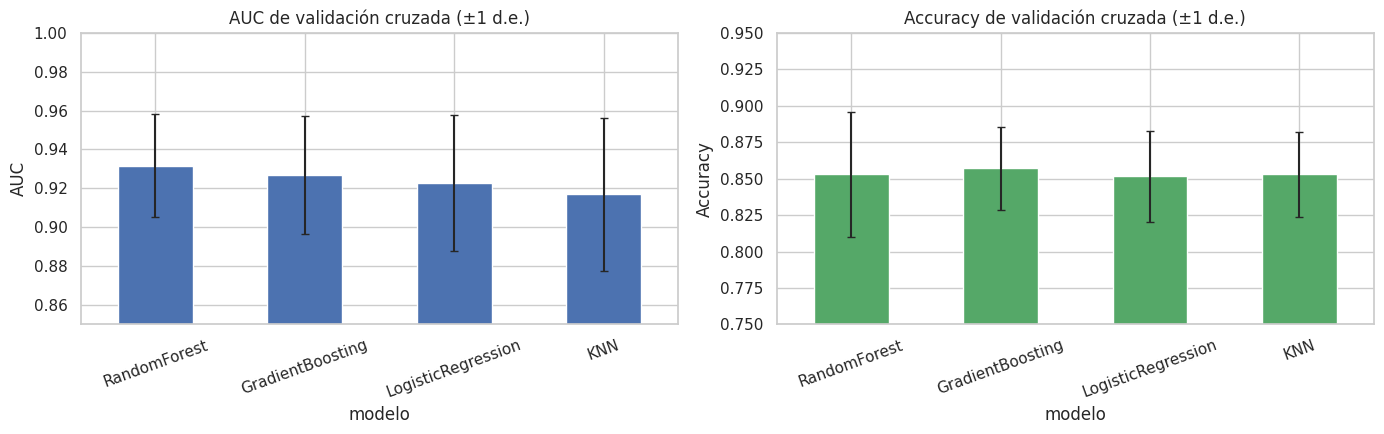

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
r = ranking.set_index("modelo")

r["auc_cv"].plot.bar(ax=axes[0], yerr=r["auc_cv_std"], capsize=3,
                      color="#4C72B0", rot=20)
axes[0].set_ylim(0.85, 1.0)
axes[0].set_title("AUC de validación cruzada (±1 d.e.)")
axes[0].set_ylabel("AUC")

r["accuracy_cv"].plot.bar(ax=axes[1], yerr=r["accuracy_cv_std"], capsize=3,
                           color="#55A868", rot=20)
axes[1].set_ylim(0.75, 0.95)
axes[1].set_title("Accuracy de validación cruzada (±1 d.e.)")
axes[1].set_ylabel("Accuracy")
plt.tight_layout(); plt.show()

In [19]:
mejor = ranking.iloc[0]
print(f"Modelo ganador por validación cruzada: {mejor['modelo']}")
print(f"  AUC CV = {mejor['auc_cv']:.4f} ± {mejor['auc_cv_std']:.4f}")
print(f"  Accuracy CV = {mejor['accuracy_cv']:.4f} ± {mejor['accuracy_cv_std']:.4f}")
print(f"Mejores hiperparámetros: {mejor['mejores_parametros']}")
print()
print(f"Diferencia entre el 1.º y el 4.º en AUC CV: "
      f"{ranking['auc_cv'].max() - ranking['auc_cv'].min():.4f}")

Modelo ganador por validación cruzada: RandomForest
  AUC CV = 0.9316 ± 0.0264
  Accuracy CV = 0.8529 ± 0.0431
Mejores hiperparámetros: {'max_depth': 8, 'min_samples_leaf': 5, 'n_estimators': 200}

Diferencia entre el 1.º y el 4.º en AUC CV: 0.0147


## 6. Conclusiones de la Etapa 1

- Los cuatro modelos alcanzan AUC de validación cruzada entre ~0.92 y ~0.93. Las diferencias entre ellos son del mismo orden que la desviación estándar entre pliegues, así que **en la práctica tienen un desempeño equivalente**; el ranking debe leerse con esa cautela (como advierte el curso en la sección 10.9).
- El modelo con mayor AUC de validación cruzada se lleva a la Etapa 2 para su evaluación detallada, verificación de sobreajuste y exportación.
- El experimento de fuga muestra que un AUC cercano a 1 en un problema clínico como este es una señal de alarma, no un logro: lo primero es revisar si alguna variable contiene la respuesta y si el preprocesamiento se ajustó antes de partir los datos.
- Como referencia, el SVC del flujo correcto de la sección 4 (escenario D) obtuvo un AUC de prueba de 0.918, frente a 0.925 del Random Forest ganador en la Etapa 2: el SVC queda al mismo nivel que los modelos del ranking.